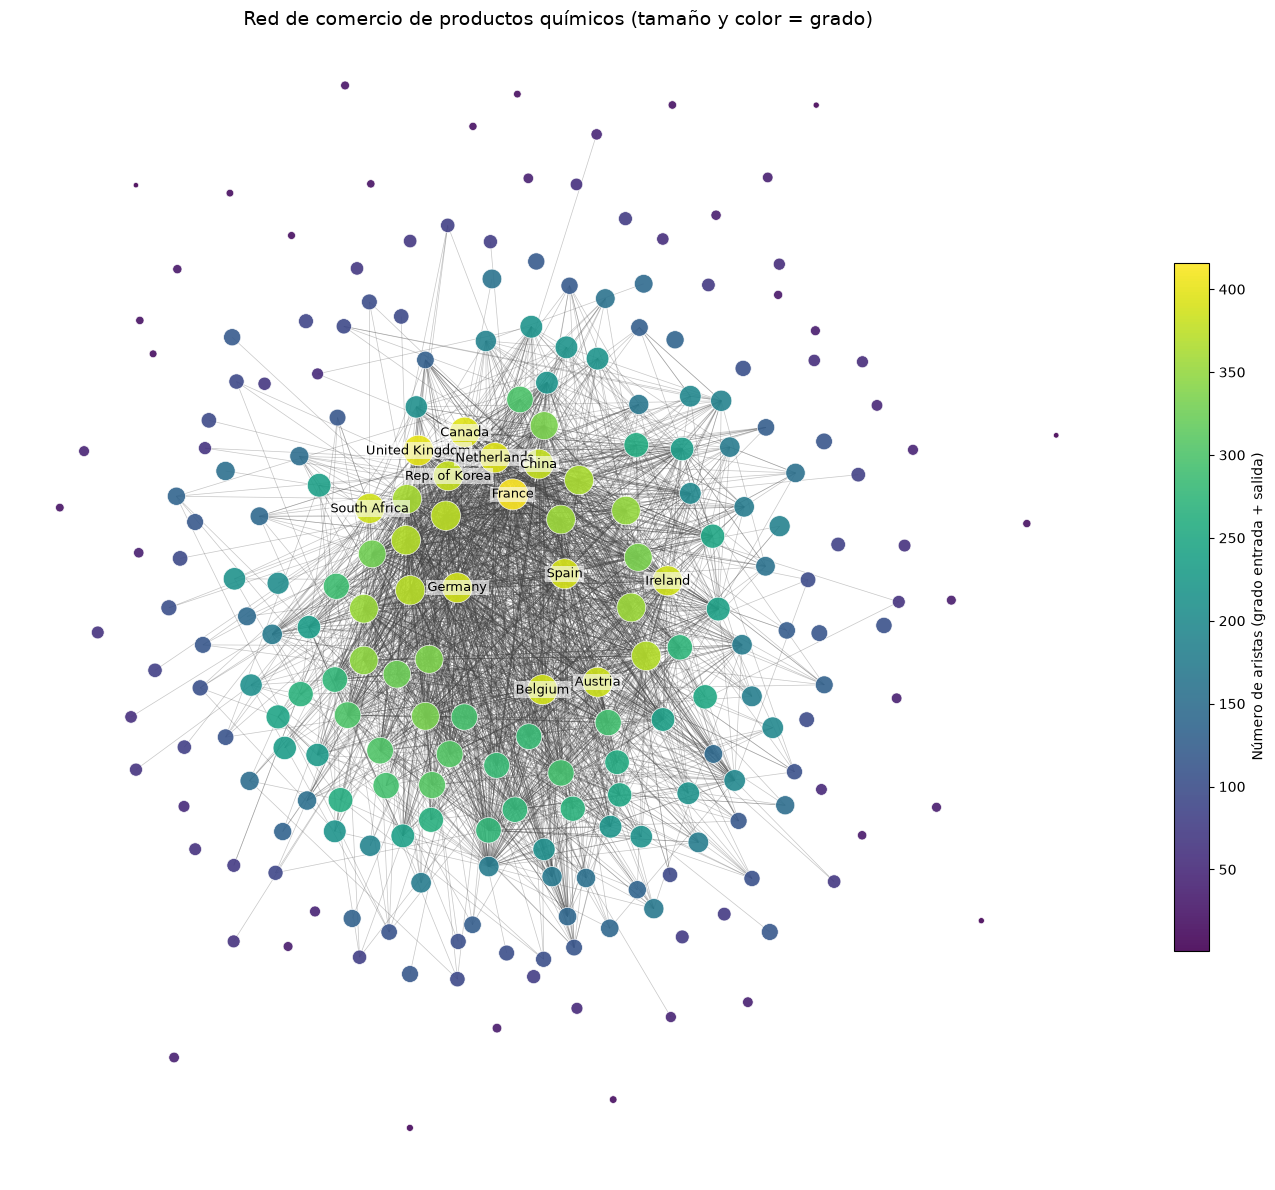

Nodos: 229 | Aristas: 18283 | Aristas dibujadas: 2743


In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# ---------------- Parámetros que puedes ajustar ----------------
RUTA_CSV = "Data_Set/Red_Quimica_Comercio.csv"
SALIDA = "Imagenes/grafo_comercio.png"
TAM_MIN, TAM_MAX = 15, 500    # tamaño mínimo y máximo de los nodos
EXPONENTE = 1.0               # >1 exagera la diferencia entre hubs y nodos pequeños
N_ETIQUETAS = 12              # solo se rotulan los N países con más aristas
K_LAYOUT = 0.35               # más alto = nodos más separados
ITERACIONES = 200             # iteraciones del layout (más = más estable)
FACTOR_RADIAL = 0.5           # <1 abre el centro y acerca la periferia (1 = sin cambio)
SEPARAR_SOLAPES = True        # empuja los nodos que se tapan entre sí
PCT_ARISTAS = 15              # % de aristas más pesadas que se dibujan (None = todas)
# ---------------------------------------------------------------

df = pd.read_csv(RUTA_CSV)

G = nx.from_pandas_edgelist(
    df,
    source="Origen",
    target="Destino",
    edge_attr=["Peso_Volumen", "Resistencia_Ruta"],
    create_using=nx.DiGraph(),
)
G.remove_edges_from(nx.selfloop_edges(G))

# Tamaño de nodo = número de aristas (grado de entrada + grado de salida)
grado = dict(G.degree())
g = np.array([grado[n] for n in G.nodes()], dtype=float)
g_norm = (g - g.min()) / (g.max() - g.min())
tamanos = TAM_MIN + (TAM_MAX - TAM_MIN) * g_norm ** EXPONENTE

# La posición se calcula con TODAS las aristas
pos = nx.spring_layout(G, k=K_LAYOUT, iterations=ITERACIONES, seed=42)

# Reescalado radial: separa el núcleo denso y acerca los nodos lejanos,
# para aprovechar mejor el espacio de la figura (se conservan los ángulos)
xy = np.array([pos[n] for n in G.nodes()])
centro = np.median(xy, axis=0)
d = xy - centro
r = np.linalg.norm(d, axis=1)
r_ref = np.percentile(r, 90)
r_nuevo = r_ref * (r / r_ref) ** FACTOR_RADIAL
r_nuevo = np.minimum(r_nuevo, 1.3 * r_ref)   # evita que unos pocos nodos lejanos estiren la figura
escala = np.divide(r_nuevo, r, out=np.zeros_like(r), where=r > 0)
xy = centro + d * escala[:, None]


def separar_solapes(xy, tam, ancho_pt=650, iteraciones=400, holgura=1.15):
    """Aleja los nodos cuyos círculos se solapan (tam = tamaño en puntos^2)."""
    xy = xy + np.random.default_rng(0).normal(scale=1e-6, size=xy.shape)
    diam_pt = np.sqrt(tam)
    for _ in range(iteraciones):
        rango = max(np.ptp(xy[:, 0]), np.ptp(xy[:, 1]))
        dmin = (diam_pt[:, None] + diam_pt[None, :]) / 2 * holgura * rango / ancho_pt
        dif = xy[:, None, :] - xy[None, :, :]
        dist = np.linalg.norm(dif, axis=2)
        np.fill_diagonal(dist, np.inf)
        solape = np.clip(dmin - dist, 0, None)
        if solape.max() == 0:
            break
        dirs = dif / dist[..., None]
        xy = xy + 0.25 * (dirs * solape[..., None]).sum(axis=1)
    return xy


if SEPARAR_SOLAPES:
    xy = separar_solapes(xy, tamanos)

pos = {n: xy[i] for i, n in enumerate(G.nodes())}

# Solo para dibujar: quedarse con las aristas de mayor volumen
if PCT_ARISTAS is None:
    aristas_dibujo = list(G.edges())
else:
    pesos = np.array([d["Peso_Volumen"] for _, _, d in G.edges(data=True)])
    umbral = np.percentile(pesos, 100 - PCT_ARISTAS)
    aristas_dibujo = [(u, v) for u, v, d in G.edges(data=True) if d["Peso_Volumen"] >= umbral]

fig, ax = plt.subplots(figsize=(14, 12))

nx.draw_networkx_edges(
    G, pos, edgelist=aristas_dibujo, ax=ax,
    arrows=False, edge_color="#444444", alpha=0.30, width=0.5,
)
nodos = nx.draw_networkx_nodes(
    G, pos, ax=ax, node_size=tamanos,
    node_color=g, cmap=plt.cm.viridis,
    edgecolors="white", linewidths=0.5, alpha=0.9,
)

top = sorted(grado, key=grado.get, reverse=True)[:N_ETIQUETAS]
nx.draw_networkx_labels(
    G, pos, labels={n: n for n in top}, ax=ax, font_size=9,
    bbox=dict(facecolor="white", alpha=0.6, edgecolor="none", pad=1),
)

plt.colorbar(nodos, ax=ax, shrink=0.6, label="Número de aristas (grado entrada + salida)")
ax.set_title("Red de comercio de productos químicos (tamaño y color = grado)", fontsize=14)
ax.axis("off")
plt.tight_layout()
plt.savefig(SALIDA, dpi=300, bbox_inches="tight")
plt.show()

print(f"Nodos: {G.number_of_nodes()} | Aristas: {G.number_of_edges()} "
      f"| Aristas dibujadas: {len(aristas_dibujo)}")



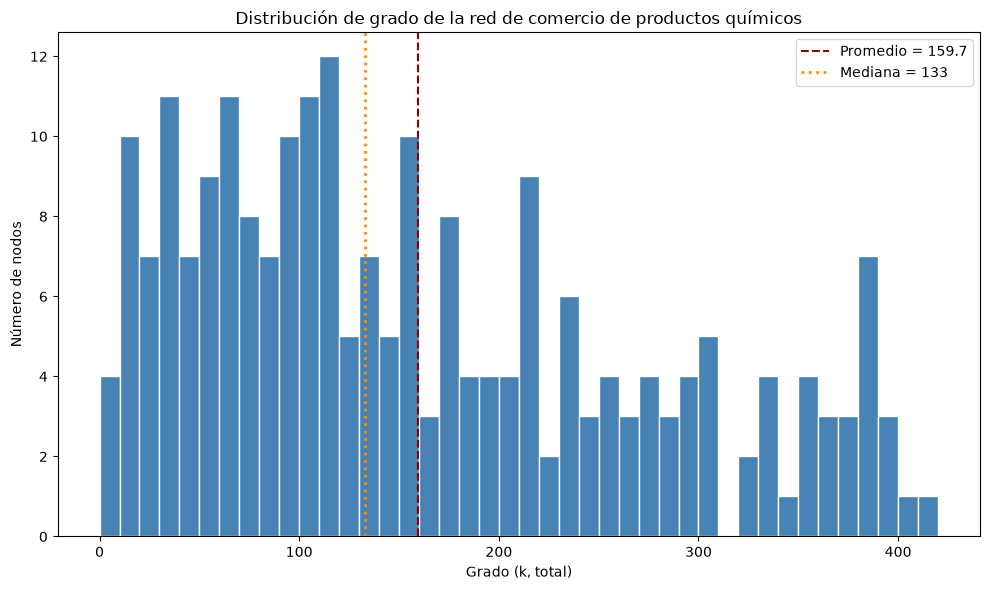

Nodos: 229 | mínimo: 1 | máximo: 416 | promedio: 159.7 | mediana: 133


In [2]:
RUTA_CSV = "Data_Set/Red_Quimica_Comercio.csv"
SALIDA = "Imagenes/distribucion_grado.png"
TIPO_GRADO = "total"      # "total" (entrada + salida), "entrada" o "salida"
ANCHO_BARRA = 10          # ancho de cada barra en unidades de grado

df = pd.read_csv(RUTA_CSV)
G = nx.from_pandas_edgelist(df, "Origen", "Destino", create_using=nx.DiGraph())
G.remove_edges_from(nx.selfloop_edges(G))

if TIPO_GRADO == "entrada":
    grados = np.array([d for _, d in G.in_degree()])
elif TIPO_GRADO == "salida":
    grados = np.array([d for _, d in G.out_degree()])
else:
    grados = np.array([d for _, d in G.degree()])

bordes = np.arange(0, grados.max() + ANCHO_BARRA, ANCHO_BARRA)

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(grados, bins=bordes, color="steelblue", edgecolor="white")
ax.axvline(grados.mean(), color="darkred", linestyle="--", linewidth=1.5,
           label=f"Promedio = {grados.mean():.1f}")
ax.axvline(np.median(grados), color="darkorange", linestyle=":", linewidth=2,
           label=f"Mediana = {np.median(grados):.0f}")
ax.set_xlabel(f"Grado (k, {TIPO_GRADO})")
ax.set_ylabel("Número de nodos")
ax.set_title("Distribución de grado de la red de comercio de productos químicos")
ax.legend()
plt.tight_layout()
plt.savefig(SALIDA, dpi=300)
plt.show()

print(f"Nodos: {len(grados)} | mínimo: {grados.min()} | máximo: {grados.max()} "
      f"| promedio: {grados.mean():.1f} | mediana: {np.median(grados):.0f}")

In [3]:
import dash
from dash import html
import dash_cytoscape as cyto
import pandas as pd
import numpy as np
import os

# Cargar extensiones de layout de Cytoscape
cyto.load_extra_layouts()


print("Preparando datos para la visualización interactiva...")
CARPETA_SALIDA = "Data_Set"

# 1. Cargar las tablas de centralidades y aristas (Asumiendo que ya corriste el código previo)
nodos = pd.read_csv(os.path.join(CARPETA_SALIDA, "centralidades_nodos.csv"))

# Cargamos el archivo base de aristas (o el de exportaciones/importaciones según tu selección)
df_aristas = pd.read_csv(RUTA_CSV)

# 2. Filtrar solo el Top 3 de socios comerciales (por volumen) para cada país de Origen[cite: 2]
# Esto evita la "bola de pelo" incomprensible y muestra la estructura central.
aristas_top = df_aristas.sort_values(['Origen', 'Peso_Volumen'], ascending=[True, False])
aristas_top = aristas_top.groupby('Origen').head(3).copy()

elements = []

# 3. Definir los NODOS para Cytoscape
# Tamaño basado en 'volumen_total' (Fuerza/Strength económica)
# Color basado en 'pagerank' (Influencia global)
max_vol = nodos['volumen_total'].max()
min_vol = nodos['volumen_total'].min()

for _, row in nodos.iterrows():
    pais = row['pais']
    # Normalización Min-Max para el tamaño del nodo (entre 15 y 90 px para visualización web)
    # Utilizamos el volumen total de transacciones (importaciones + exportaciones)[cite: 6]
    size = 15 + 75 * ((row['volumen_total'] - min_vol) / (max_vol - min_vol + 1e-9))

    # Asignar color según PageRank: Valores altos (cerca de 1) serán más naranjas/rojos, bajos más pálidos.
    pr_norm = row['pagerank'] / (nodos['pagerank'].max() + 1e-9)
    # Genera un gradiente RGB desde amarillo hasta rojo oscuro
    r = 255
    g = int(255 * (1 - pr_norm))
    b = 0
    color = f"rgba({r}, {g}, {b}, 0.9)"

    elements.append({
        'data': {
            'id': pais,
            'label': pais,
            'size': size,
            'color': color
        }
    })

# 4. Definir las ARISTAS para Cytoscape
for _, row in aristas_top.iterrows():
    elements.append({
        'data': {
            'source': row['Origen'],
            'target': row['Destino'],
            'peso': row['Peso_Volumen']
        }
    })

# 5. Configurar los estilos visuales del Dashboard[cite: 2]
stylesheet = [
    {
        'selector': 'node',
        'style': {
            'label': 'data(label)',
            'width': 'data(size)',
            'height': 'data(size)',
            'background-color': 'data(color)',
            'color': '#ffffff',  # Texto blanco
            'font-size': '10px',
            'text-valign': 'center',
            'text-halign': 'center',
            'border-width': 1.5,
            'border-color': '#ffffff'
        }
    },
    {
        'selector': 'edge',
        'style': {
            'width': 1.5,
            'line-color': '#555555',
            'target-arrow-color': '#555555',
            'target-arrow-shape': 'triangle',
            'curve-style': 'bezier',
            'opacity': 0.4
        }
    }
]

# 6. Lanzar la aplicación Dash
app = dash.Dash(__name__)

app.layout = html.Div(style={'backgroundColor': '#010103', 'padding': '20px'}, children=[
    html.H2(f"Red Global de Comercio Químico", style={'color': 'white', 'fontFamily': 'sans-serif'}),
    html.P("Tamaño del nodo: Volumen Comercial Total (Strength). Color: PageRank (Rojo=Mayor Influencia). Se muestran los Top 3 socios por país.", style={'color': '#aaaaaa', 'fontFamily': 'sans-serif'}),
    cyto.Cytoscape(
        id='red-interactiva',
        layout={'name': 'cola'}, # Usamos el algoritmo 'cola' para distribuir los nodos de forma orgánica
        style={'width': '100%', 'height': '700px'},
        elements=elements,
        stylesheet=stylesheet
    )
])

print("\n¡Iniciando visualización! El gráfico interactivo aparecerá debajo.")
app.run(jupyter_mode="inline", port=8050)

Preparando datos para la visualización interactiva...

¡Iniciando visualización! El gráfico interactivo aparecerá debajo.


--- VISUALIZACIÓN DESPEJADA DE COMUNIDADES (TOP 3 ENLACES) ---


NameError: name 'TIPO_RED' is not defined

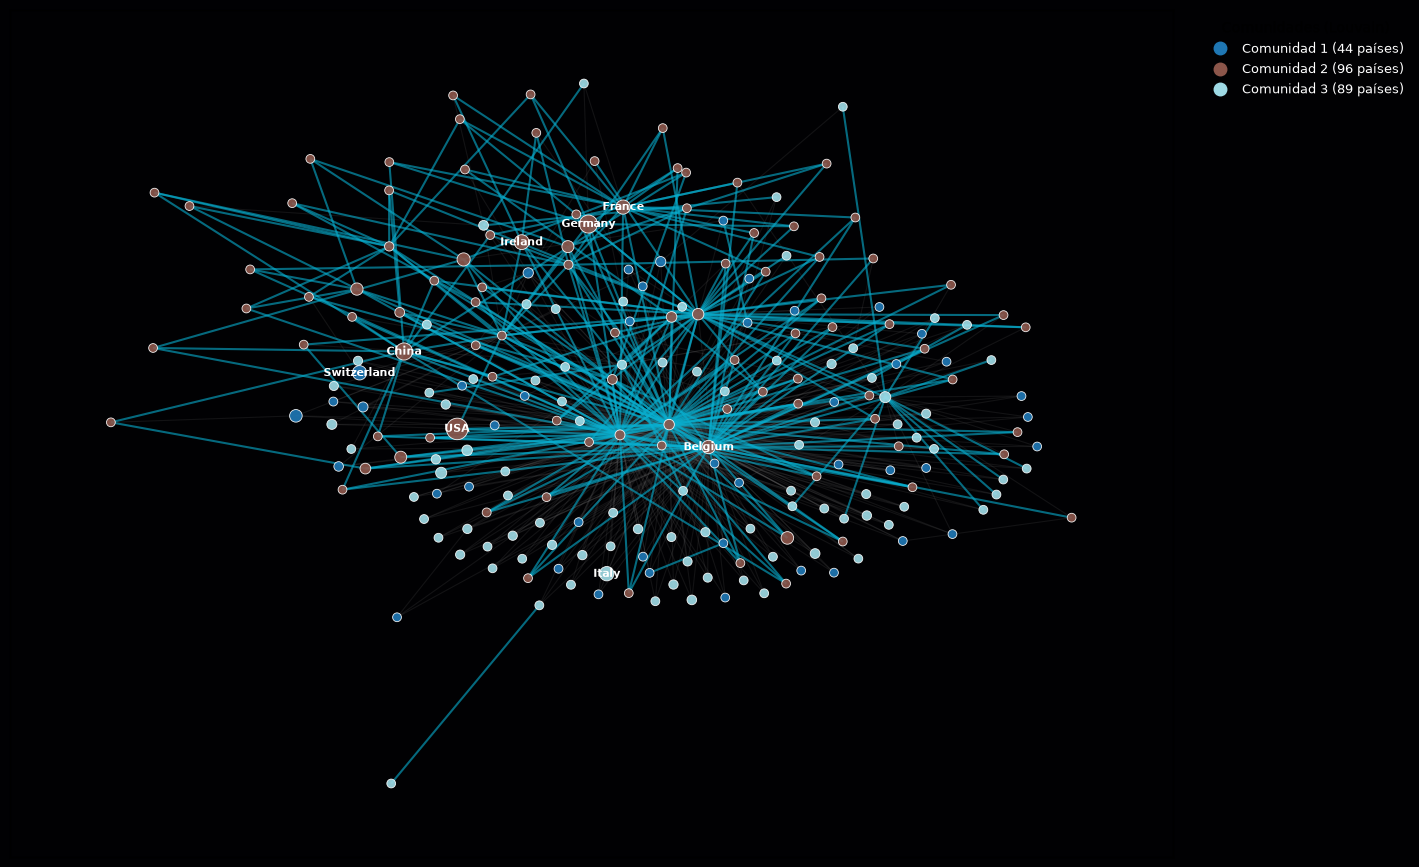

In [4]:
import os
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib as mpl
import networkx as nx
import pandas as pd
import numpy as np

print("--- VISUALIZACIÓN DESPEJADA DE COMUNIDADES (TOP 3 ENLACES) ---")

# 1. Asegurar la proyección no dirigida ponderada U
U = nx.Graph()
U.add_nodes_from(G.nodes())
for u, v, d in G.edges(data=True):
    peso = d.get("Peso_Volumen", 1.0)
    if U.has_edge(u, v):
        U[u][v]["weight"] += peso
    else:
        U.add_edge(u, v, weight=peso)

# 2. Detección de comunidades de Louvain
comunidades_louvain = list(nx.community.louvain_communities(U, weight="weight", seed=42))
comunidad_map = {nodo: i for i, com in enumerate(comunidades_louvain) for nodo in com}
num_comunidades = len(comunidades_louvain)

# 3. FILTRO CLAVE: Extraer solo los 3 enlaces más fuertes por nodo
aristas_relevantes = set()
for nodo in U.nodes():
    vecinos = list(U.edges(nodo, data=True))
    # Ordenar enlaces del nodo por su peso económico descendente
    vecinos_top = sorted(vecinos, key=lambda x: x[2].get("weight", 0), reverse=True)[:3]
    for u, v, _ in vecinos_top:
        aristas_relevantes.add(tuple(sorted((u, v))))

# Subgrafo visual que contiene todos los nodos pero solo los enlaces Top 3
U_visual = nx.Graph()
U_visual.add_nodes_from(U.nodes())
for u, v in aristas_relevantes:
    U_visual.add_edge(u, v, weight=U[u][v]["weight"])

# 4. Calcular el layout espacial sobre la red filtrada
# Al haber eliminado los enlaces secundarios, spring_layout agrupa los clústeres limpiamente
pos = nx.spring_layout(U_visual, weight="weight", seed=42, k=0.45, iterations=60)

# Separar aristas internas (misma comunidad) vs externas (entre comunidades)
aristas_internas = [(u, v) for u, v in U_visual.edges() if comunidad_map[u] == comunidad_map[v]]
aristas_externas = [(u, v) for u, v in U_visual.edges() if comunidad_map[u] != comunidad_map[v]]

# 5. Configurar visualización
plt.figure(figsize=(15, 11), facecolor="#010103")
ax = plt.gca()
ax.set_facecolor("#010103")

try:
    cmap = mpl.colormaps["tab20"].resampled(max(num_comunidades, 1))
except (AttributeError, KeyError):
    cmap = plt.cm.get_cmap("tab20", max(num_comunidades, 1))

# Dibujar aristas: enlaces externos tenues y delgados; internos nítidos
nx.draw_networkx_edges(U_visual, pos, edgelist=aristas_externas, alpha=0.15, edge_color="#777777", width=0.8)
nx.draw_networkx_edges(U_visual, pos, edgelist=aristas_internas, alpha=0.60, edge_color="#08B0D1", width=1.5)

# Determinar tamaño de nodos basado en el volumen total (si existe en nodos)
colores_nodos = [comunidad_map[nodo] for nodo in U_visual.nodes()]
if "volumen_total" in nodos.columns:
    vol_dict = dict(zip(nodos["pais"] if "pais" in nodos.columns else nodos.index, nodos["volumen_total"]))
    max_v = max(vol_dict.values()) if vol_dict else 1.0
    tamanos_nodos = [40 + 200 * (vol_dict.get(nodo, 0) / max_v) for nodo in U_visual.nodes()]
else:
    tamanos_nodos = 80

# Dibujar nodos
nx.draw_networkx_nodes(
    U_visual,
    pos,
    node_color=colores_nodos,
    cmap=cmap,
    node_size=tamanos_nodos,
    alpha=0.92,
    edgecolors="white",
    linewidths=0.6
)

# Rotular únicamente los 8 países más importantes en volumen para no saturar
if "pais" in nodos.columns:
    top_labels = nodos.sort_values(by="volumen_total", ascending=False)["pais"].head(8).tolist()
elif "volumen_total" in nodos.columns:
    top_labels = nodos.sort_values(by="volumen_total", ascending=False).index.head(8).tolist()
else:
    top_labels = list(U_visual.nodes())[:8]

labels_dict = {p: p for p in top_labels if p in pos}
nx.draw_networkx_labels(U_visual, pos, labels=labels_dict, font_size=8, font_color="white", font_weight="bold")

# 6. Leyenda de comunidades
leyenda_elementos = []
for i, com in enumerate(comunidades_louvain):
    color = cmap(i)
    marcador = mlines.Line2D(
        [], [], color=color, marker='o', linestyle='None',
        markersize=9, label=f'Comunidad {i+1} ({len(com)} países)'
    )
    leyenda_elementos.append(marcador)

plt.legend(
    handles=leyenda_elementos,
    title="Comunidades (Louvain)",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
    fontsize=9,
    title_fontsize=10,
    labelcolor="white"
)

plt.title(f"Comunidades de Louvain - Principales Flujos Comerciales ({TIPO_RED})", color="white", fontsize=14, pad=20)
plt.axis("off")
plt.tight_layout()

ruta_salida = os.path.join(CARPETA_SALIDA, "comunidades_filtradas_top3.png")
plt.savefig(ruta_salida, dpi=300, facecolor="#010103", bbox_inches="tight")
plt.show()

print(f"Gráfico filtrado guardado en: {ruta_salida}")

In [ ]:
import os
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from pyvis.network import Network
from IPython.display import IFrame, display

print("--- GENERANDO VISUALIZACIÓN INTERACTIVA DE COMUNIDADES ---")

# 1. Asegurar la proyección no dirigida ponderada U
U = nx.Graph()
U.add_nodes_from(G.nodes())
for u, v, d in G.edges(data=True):
    peso = d.get("Peso_Volumen", 1.0)
    if U.has_edge(u, v):
        U[u][v]["weight"] += peso
    else:
        U.add_edge(u, v, weight=peso)

# 2. Detección de comunidades con Louvain (semilla fija)
comunidades_louvain = list(nx.community.louvain_communities(U, weight="weight", seed=42))
comunidad_map = {nodo: i for i, com in enumerate(comunidades_louvain) for nodo in com}
num_com = len(comunidades_louvain)

# Asignar paleta de colores hexadecimales a cada comunidad
# Asignar paleta de colores hexadecimales a cada comunidad
try:
    cmap = mpl.colormaps["tab20"].resampled(max(num_com, 1))
except (AttributeError, KeyError):
    import matplotlib.pyplot as plt
    cmap = plt.cm.get_cmap("tab20", max(num_com, 1))

colores_comunidad = [mcolors.to_hex(cmap(i)) for i in range(num_com)]

# 3. Filtrar Top 3 enlaces más fuertes por nodo
aristas_relevantes = set()
for nodo in U.nodes():
    vecinos = list(U.edges(nodo, data=True))
    vecinos_top = sorted(vecinos, key=lambda x: x[2].get("weight", 0), reverse=True)[:3]
    for u, v, _ in vecinos_top:
        aristas_relevantes.add(tuple(sorted((u, v))))

# 4. Inicializar red de PyVis con tema oscuro
net = Network(
    height="750px",
    width="100%",
    bgcolor="#010103",
    font_color="#ffffff",
    directed=False,
    notebook=True,
    cdn_resources="remote"
)

# Mapear volumen total para el tamaño del nodo (si existe en tu DataFrame de nodos)
if "volumen_total" in nodos.columns:
    vol_dict = dict(zip(nodos["pais"] if "pais" in nodos.columns else nodos.index, nodos["volumen_total"]))
    max_vol = max(vol_dict.values()) if vol_dict else 1.0
else:
    vol_dict = {}
    max_vol = 1.0

# 5. Agregar NODOS a PyVis
for nodo in U.nodes():
    com_id = comunidad_map.get(nodo, 0)
    color = colores_comunidad[com_id]
    vol = vol_dict.get(nodo, 0)

    # Tamaño proporcional (entre 12 y 45 px)
    size = 12 + 33 * (vol / (max_vol + 1e-9))

    # Texto emergente al pasar el cursor (hover tooltip)
    tooltip = (
        f"<b>País:</b> {nodo}<br>"
        f"<b>Comunidad:</b> {com_id + 1}<br>"
        f"<b>Volumen total:</b> ${vol:,.2f}" if vol > 0 else f"<b>País:</b> {nodo}<br><b>Comunidad:</b> {com_id + 1}"
    )

    net.add_node(
        n_id=nodo,
        label=nodo,
        title=tooltip,
        color=color,
        size=size,
        borderWidth=1.5,
        borderWidthSelected=3
    )

# 6. Agregar ARISTAS (Top 3) diferenciando intra vs inter comunidad
for u, v in aristas_relevantes:
    peso = U[u][v].get("weight", 1.0)
    misma_comunidad = (comunidad_map[u] == comunidad_map[v])

    if misma_comunidad:
        color_borde = "#08B0D1" # Cian brillante para enlaces internos
        opacidad = 0.65
        width = 2.0
    else:
        color_borde = "#555555" # Gris tenue para enlaces entre comunidades
        opacidad = 0.20
        width = 0.8

    net.add_edge(
        source=u,
        to=v,
        title=f"Volumen: ${peso:,.2f}",
        color={"color": color_borde, "opacity": opacidad},
        width=width
    )

# 7. Configuración del motor de físicas (ForceAtlas2) para clústeres limpios
net.force_atlas_2based(
    gravity=-50,
    central_gravity=0.01,
    spring_length=100,
    spring_strength=0.08,
    damping=0.4
)

# 8. Guardar y desplegar en el notebook
ruta_html = os.path.join(CARPETA_SALIDA, "red_interactiva_comunidades.html")
net.write_html(ruta_html)

print(f"Visualización interactiva guardada en: {ruta_html}")

--- GENERANDO VISUALIZACIÓN INTERACTIVA DE COMUNIDADES ---
Visualización interactiva guardada en: Data_Set/red_interactiva_comunidades.html


In [ ]:
import os
import pandas as pd

print("--- EXPORTANDO ARISTAS CON ASIGNACIÓN DE COMUNIDADES ---")

# 1. Asegurar el mapeo país -> comunidad (índice 1, 2, ...)
comunidad_map_1based = {}
for i, com in enumerate(comunidades_louvain, start=1):
    for nodo in com:
        comunidad_map_1based[nodo] = i

# 2. Construir la lista de aristas con metadatos
filas_red = []
for u, v in aristas_relevantes:
    peso = U[u][v].get("weight", 0.0)
    c_u = comunidad_map_1based.get(u, None)
    c_v = comunidad_map_1based.get(v, None)

    filas_red.append({
        'origen': u,
        'comunidad_origen': c_u,
        'destino': v,
        'comunidad_destino': c_v,
        'peso_volumen': peso,
        'misma_comunidad': (c_u == c_v)
    })

# 3. Crear DataFrame y ordenar por peso comercial descendente
df_red_completa = pd.DataFrame(filas_red)
df_red_completa = df_red_completa.sort_values(by='peso_volumen', ascending=False).reset_index(drop=True)

# 4. Guardar archivo CSV
ruta_csv_red = os.path.join(CARPETA_SALIDA, f"red_comunidades.csv")
df_red_completa.to_csv(ruta_csv_red, index=False)

print(f"Archivo exportado exitosamente en: {ruta_csv_red}")
print(f"Total de enlaces registrados: {len(df_red_completa)}")
display(df_red_completa.head(10))

--- EXPORTANDO ARISTAS CON ASIGNACIÓN DE COMUNIDADES ---
Archivo exportado exitosamente en: Data_Set/red_comunidades.csv
Total de enlaces registrados: 677


,origen,comunidad_origen,destino,comunidad_destino,peso_volumen,misma_comunidad
0,Australia,2,Lao People's Dem. Rep.,2,2.0,True
1,Australia,2,Viet Nam,3,2.0,False
2,Canada,2,Seychelles,2,2.0,True
3,Belgium,2,Côte d'Ivoire,1,2.0,False
4,Australia,2,Niger,1,2.0,False
5,Australia,2,Qatar,3,2.0,False
6,American Samoa,2,France,2,2.0,True
7,Austria,2,Canada,2,2.0,True
8,Australia,2,North Macedonia,3,2.0,False
9,Afghanistan,2,Saudi Arabia,3,2.0,False


In [ ]:
import networkx as nx
import pandas as pd
import numpy as np

def calcular_metricas_robustez(Grafo, nombre_escenario):
    n = Grafo.number_of_nodes()
    m = Grafo.number_of_edges()

    # Componentes conexas
    n_wcc = nx.number_weakly_connected_components(Grafo)
    n_scc = nx.number_strongly_connected_components(Grafo)

    # Mayor componente fuertemente conexa (SCC)
    if n > 0 and m > 0:
        scc_nodos = max(nx.strongly_connected_components(Grafo), key=len)
        tam_scc = len(scc_nodos)
        frac_scc = tam_scc / n
        Gs = Grafo.subgraph(scc_nodos).copy()

        # Diámetro y camino promedio en el núcleo
        try:
            diametro = nx.diameter(Gs)
            camino_prom = nx.average_shortest_path_length(Gs)
        except Exception:
            diametro, camino_prom = np.nan, np.nan
    else:
        tam_scc, frac_scc, diametro, camino_prom = 0, 0, np.nan, np.nan

    # Nodos totalmente desconectados (sin importaciones ni exportaciones)
    nodos_aislados = sum(1 for node in Grafo.nodes() if Grafo.degree(node) == 0)

    return {
        "Escenario": nombre_escenario,
        "Nodos": n,
        "Aristas": m,
        "Tamaño Mayor SCC": tam_scc,
        "Fracción en SCC": round(frac_scc, 4),
        "Componentes Fuertes": n_scc,
        "Nodos Aislados": nodos_aislados,
        "Camino Promedio (SCC)": round(camino_prom, 3) if not np.isnan(camino_prom) else "N/A",
        "Diámetro (SCC)": diametro if not np.isnan(diametro) else "N/A"
    }

print("--- SIMULACIÓN DE ESCENARIOS DE ATAQUE ---")

# 1. Medir Red Normal (Línea base)
metricas_base = calcular_metricas_robustez(G, "Red Normal")

# 2. Definir los Nodos a Atacar (Top 5 en Intermediación / Betweenness)
# Alternativamente puedes usar 'volumen_exportado' o 'grado_total'
nodos_df = pd.read_csv(os.path.join(CARPETA_SALIDA, "centralidades_nodos.csv"))
top_ataque_betweenness = nodos_df.sort_values(by="intermediacion", ascending=False)["pais"].head(5).tolist()
top_ataque_volumen = nodos_df.sort_values(by="volumen_exportado", ascending=False)["pais"].head(5).tolist()

print(f"Top 5 atacados por Intermediación (Puentes): {top_ataque_betweenness}")
print(f"Top 5 atacados por Volumen (Productores clave): {top_ataque_volumen}")

# 3. Escenario 1: Ataque Dirigido a Nodos Puente (Betweenness)
G_ataque_betw = G.copy()
G_ataque_betw.remove_nodes_from(top_ataque_betweenness)
metricas_betw = calcular_metricas_robustez(G_ataque_betw, "Ataque Top 5 Betweenness")

# 4. Escenario 2: Ataque Dirigido a Nodos Productores (Volumen Exportado)
G_ataque_vol = G.copy()
G_ataque_vol.remove_nodes_from(top_ataque_volumen)
metricas_vol = calcular_metricas_robustez(G_ataque_vol, "Ataque Top 5 Volumen Exportado")

# 5. Escenario 3: Fallo Aleatorio (Control - 5 países al azar)
np.random.seed(42)
nodos_azar = np.random.choice(list(G.nodes()), size=5, replace=False)
G_azar = G.copy()
G_azar.remove_nodes_from(nodos_azar)
metricas_azar = calcular_metricas_robustez(G_azar, "Fallo Aleatorio (5 países)")

# Consolidar resultados en DataFrame
df_comparativo = pd.DataFrame([metricas_base, metricas_betw, metricas_vol, metricas_azar])
display(df_comparativo)

# Guardar reporte
df_comparativo.to_csv(os.path.join(CARPETA_SALIDA, "comparacion_escenarios_ataque.csv"), index=False)

--- SIMULACIÓN DE ESCENARIOS DE ATAQUE ---
Top 5 atacados por Intermediación (Puentes): ['USA', 'China', 'Germany', 'India', 'France']
Top 5 atacados por Volumen (Productores clave): ['USA', 'Germany', 'China', 'Ireland', 'Switzerland']


,Escenario,Nodos,Aristas,Tamaño Mayor SCC,Fracción en SCC,Componentes Fuertes,Nodos Aislados,Camino Promedio (SCC),Diámetro (SCC)
0,Red Normal,229,18283,228,0.9956,2,0,1.654,3
1,Ataque Top 5 Betweenness,224,16382,223,0.9955,2,0,1.678,3
2,Ataque Top 5 Volumen Exportado,224,16404,223,0.9955,2,0,1.677,3
3,Fallo Aleatorio (5 países),224,17103,223,0.9955,2,0,1.662,3
